# Compare the port with the original codes

This notebook runs the original fastnc TATT transform, the corrected fastnc
main-branch two-Bessel transform, and the NumPy aperture integral of Gomes et
al. (arXiv:2601.09133) on small fixed inputs, and compares each against the C
port. A separate frozen-reference section checks matter and
intrinsic-alignment bispectra against values saved from the pinned original
Python calculation. These comparisons establish that the port reproduces
specific finite numerical operators; they do not establish a DES Y3/Y6
likelihood reproduction or a survey accuracy target, because the full original
CosmoSIS analysis and the TreeCorr catalogue measurement stay outside this
notebook.

The settings cell below names the original-code directories and numerical
controls. They are independent copies under Cocoa/external_modules/code/,
with revisions and hashes recorded in `data/code_comparison_manifest.yaml`.
Edit those paths for another installation. Missing sources are reported;
no other Cocoa project or investigation folder is required. [The comparison guide](README.md#comparison) gives units, source credits and
interpretation.

**Model and data.** The settings are explicit in the Python cell below:

| Choice | Value |
| --- | --- |
| Original codes | fastnc `tatt` branch, fastnc `main` branch, and the Y3 NumPy aperture integrator, as local snapshots at pinned commits |
| Pins and hashes | `data/code_comparison_manifest.yaml`; SHA256 checks on every executed Python file |
| Grid | `nfft: 32`, `lmax: 3`, `mmax: 5`, `phi_count: 7` |
| Frozen physics | `frozen_physics: true`: the bispectrum references come from a saved fixture |
| Outputs | arrays, provenance and source stdout/stderr in `chains/code_comparison/` |
| Threads | one BLAS worker; OpenMP at `threads: 1`, capped at four |

Words used throughout:

- **TATT**, tidal alignment and tidal torquing: the intrinsic-alignment model
  of the fastnc `tatt` branch, with linear, density-weighted and quadratic
  tidal shape terms.
- A **two-Bessel transform** turns a function of two Fourier wavenumbers into a
  function of two angular separations by integrating against one Bessel
  function in each variable; fastnc evaluates it with the FFTLog algorithm on
  logarithmic grids.
- A **Mellin bias** is the power-law tilt that FFTLog applies to its input so
  the tilted function decays at both ends of the logarithmic grid.
- $\langle M_\mathrm{ap}^3\rangle$ (**Map3**) is the aperture skewness: the
  third moment of shear integrated with a compensated filter, the three-point
  summary this project predicts.
- The **natural components** $\Gamma_i$ are the four complex three-shear
  correlations that transform simply under rotations; **centroid projection**
  measures each shear relative to the direction from the galaxy to the
  triangle's centroid.
- A **frozen reference** is an array saved once from the pinned original code;
  the check reads it back by hash and never runs the original live.
- **CosmoSIS** is the original analysis framework and **TreeCorr** the
  catalogue correlation code; both stay outside these comparisons.

In [1]:
import os
from pathlib import Path
import importlib
import sys

# Set these before importing NumPy or a compiled numerical library.
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "BLIS_NUM_THREADS",
                 "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS", "GOTO_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OMP_DYNAMIC"] = "FALSE"
os.environ["MKL_DYNAMIC"] = "FALSE"

project = Path.cwd().resolve()
if not (project / "interface").is_dir():
    raise FileNotFoundError("Start this notebook with des_3pcf as its working directory.")
# Original libraries live outside the survey project. Revisions and file
# hashes are listed in data/code_comparison_manifest.yaml.
external = project.parents[1] / "external_modules" / "code"
settings = {
    "format": "des3pcf-code-comparison-v1",
    "sources": {
        "tatt": external / "fastnc_tatt",
        "main": external / "fastnc_main",
        "integrator": external / "3pcf_integrator",
    },
    "output": project / "chains" / "code_comparison",
    "threads": 1,
    "nfft": 32,
    "lmax": 3,
    "mmax": 5,
    "phi_count": 7,
    "frozen_physics": True,
}

sys.path.insert(0, str(project / "interface"))
from cosmolike_des_3pcf_notebook_wrappers import (
    comparison_status, comparison_case, comparison_summary,
    run_code_comparison, load_comparison_case,
)
plots = importlib.import_module("cosmolike_notebook_utils.3pcf")

from threadpoolctl import threadpool_info, threadpool_limits
# Environment settings do not resize pools already loaded by a reused kernel.
BLAS_LIMIT = threadpool_limits(limits=1, user_api="blas")
for pool in threadpool_info():
    if pool["user_api"] == "blas" and pool["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS pool did not accept its one-worker limit.")

import matplotlib
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['figure.dpi'] = 80


## Check the original files

A commit name states the intended version; the SHA256 hashes check the actual
Python files that will execute. The runner imports the full TATT package only
inside a fresh subprocess, so the package's mutable class configuration cannot
leak into later notebook calls, and it turns off the package's disk cache and
automatic Fourier-grid tuning through public settings.

The dependency table also names CosmoSIS and TreeCorr for context. These
standalone comparisons run without them, and their presence would not make this
notebook run the complete original pipelines.

In [2]:
availability = comparison_status(settings=settings)
display(comparison_summary(report=availability))
availability["dependencies"]


,source,commit,status,diagnostic
0,tatt,7b2336ce37a909bed51f07f32a2a4f096e71b6ce,verified,
1,main,e59eab5a07401d2f484bfe00dd48827f2d2162c7,verified,
2,integrator,d6098d326dcb03bc750adcc9627119f52d928944,verified,


{'numpy': True,
 'scipy': True,
 'astropy': True,
 'pandas': True,
 'mpi4py': True,
 'cosmosis': False,
 'treecorr': True}

## Run the comparisons

The runner starts one subprocess at a time, keeps every BLAS library at one
thread, and caps OpenMP at the settings cell's thread count. It saves the complete
arrays, the provenance, and each source's stdout and stderr in
`chains/code_comparison/`.

The table reports
$\max|x_\mathrm{port}-x_\mathrm{reference}|/\max|x_\mathrm{reference}|$ over
the complete output array, and each plot shows 100 times the difference
divided by the maximum absolute reference value of the displayed series. Both
are scaled differences with a nonzero denominator, so they stay defined where
individual components cross zero; neither is a pointwise relative error. The
zero-integral diagnostic appears separately in absolute units.

In [3]:
report = run_code_comparison(settings=settings)
comparison_summary(report=report)


,comparison,status,reference,max scaled difference,expected difference
0,bessel_tatt_untapered,completed,live_original_code,1.356102e-14,False
1,coupling_tatt_rectangle_bias,completed,live_original_code,2.441406e-04,True
2,natural_tatt_public,completed,live_original_code,4.343060e-04,False
3,natural_exact_coupling,completed,live_original_code,3.369894e-03,True
4,bessel_main_taper,completed,live_original_code,1.472269e-14,False
5,aperture_equal,completed,live_original_code,1.163271e-15,False
6,aperture_unequal,completed,live_original_code,7.579882e-01,True
7,physics_matter_frozen,completed,frozen_reference,6.429753e-06,False
8,physics_ia_mode0_frozen,completed,frozen_reference,3.805505e-15,False
9,physics_ia_mode1_frozen,completed,frozen_reference,1.686490e-15,False


## The two-Bessel transform and the Fourier taper

Both codes receive the same input samples, Mellin biases, bin width, padding
and Bessel orders. The TATT source computes a Fourier-coefficient taper but
returns the untapered coefficients, while the pinned main source returns the
tapered ones; the port therefore picks the matching mode explicitly for each
comparison.

The plot below uses the main branch's corrected taper. The TATT result sits in
the saved case `bessel_tatt_untapered`; neither result substitutes for the
other.

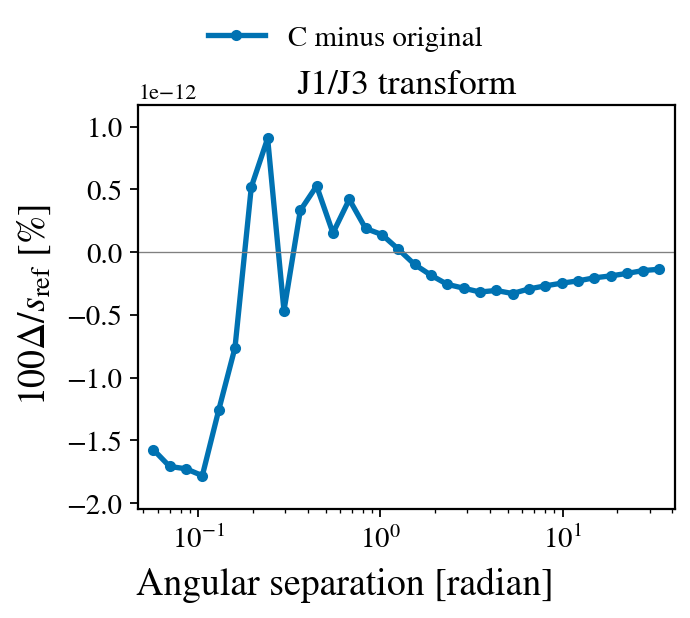

In [4]:
case = comparison_case(report=report, name="bessel_main_taper")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Angular separation [radian]",
    quantity_label="Two-Bessel transform", residual="scaled",
    xscale="log", show=1,
)


## The public TATT natural-component calculation

The four complex $\Gamma_i$ are three-shear correlations measured after fixed
rotations of the shear axes. The runner feeds a smooth symmetric set of
bispectrum multipoles through `set_bispectrum`, the original public interface.
Symmetry matters here: this fastnc branch obtains negative angular modes by
transposing positive modes, so the port uses its matching mode for this
comparison, and a general ordered source-bin triplet needs the port's
independent signed-mode calculation instead.

Both outputs use centroid projection and the same 200-node linear interpolation
for the angular coupling. The source builds its coupling table from a capped
left-endpoint rectangle integral, while the C table is analytic; the live
zero-integral diagnostic below measures the resulting source bias. The saved
case `natural_exact_coupling` removes the interpolation in C and is a different
discretization by construction. Neither residual is a survey accuracy bound,
and the saved arrays keep both real and imaginary components.

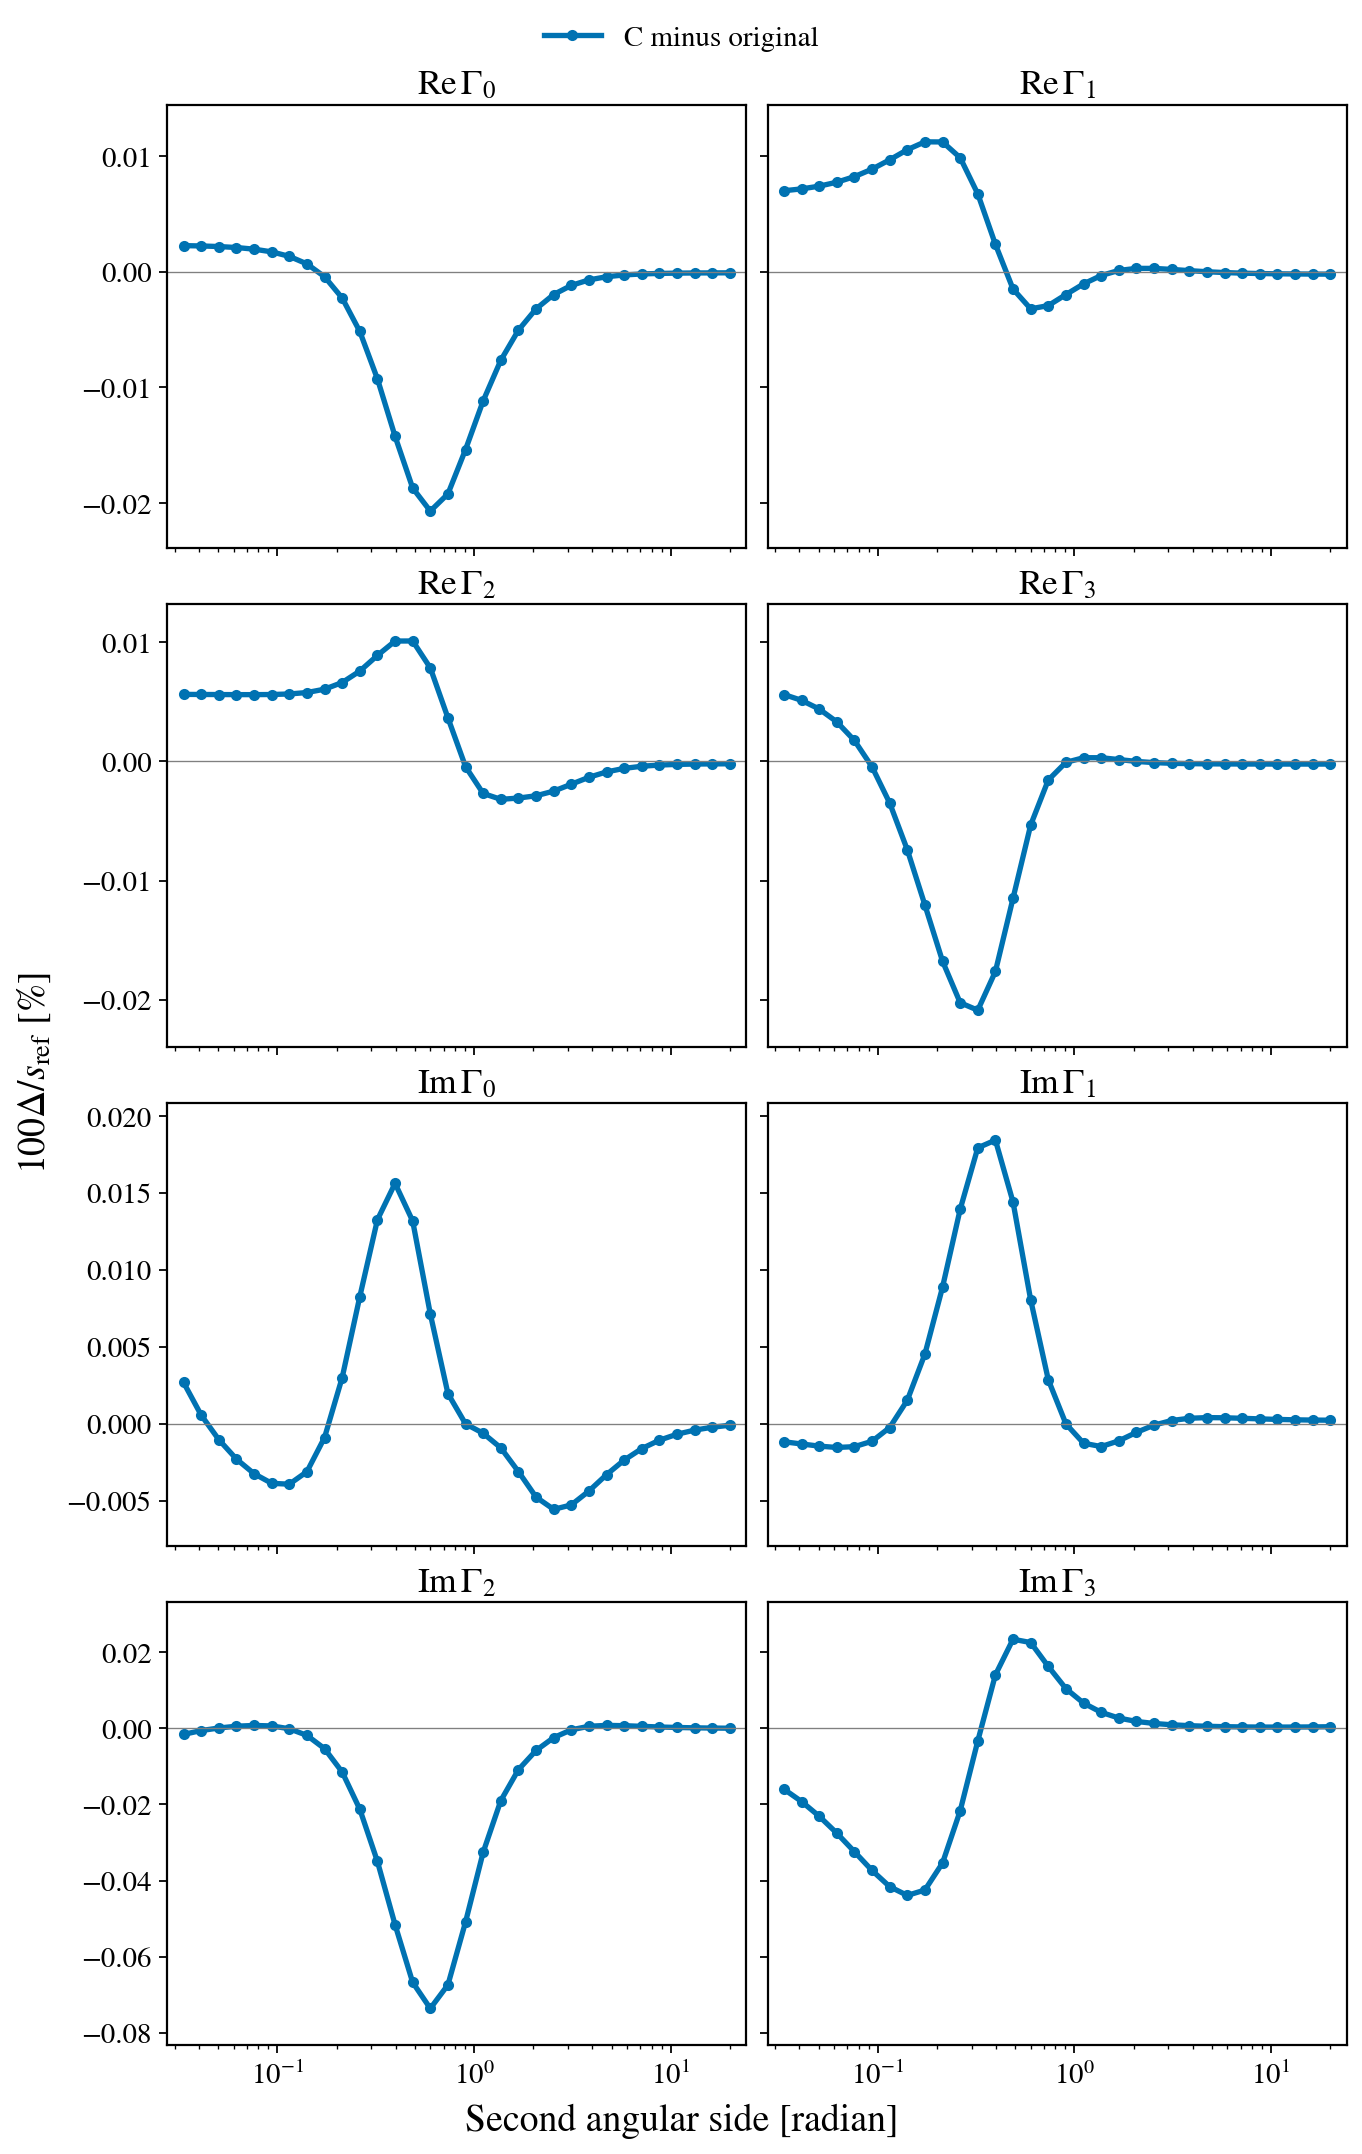

In [5]:
case = comparison_case(report=report, name="natural_tatt_public")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Second angular side [radian]",
    quantity_label="Natural shear component", residual="scaled",
    xscale="log", ncols=2, show=1,
)


The original coupling integrator stops at its default 4096-sample cap, and its
caller ignores the convergence flag. For the known integral
$4\pi\int_0^\pi\cos\delta\,d\delta=0$, its left-endpoint sum is $4\pi^2/N$. The
ladder below raises only the public integration-function iteration limit, so it
isolates this source discretization error without modifying the original code.

In [6]:
coupling_case = comparison_case(report=report, name="coupling_tatt_rectangle_bias")
coupling_case["rectangle_bias_ladder"]


[{'left_rectangle_count': 256,
  'source_integral': 0.15421256876702444,
  'predicted_bias': 0.15421256876702122,
  'converged': False},
 {'left_rectangle_count': 1024,
  'source_integral': 0.038553142191757504,
  'predicted_bias': 0.038553142191755305,
  'converged': False},
 {'left_rectangle_count': 4096,
  'source_integral': 0.009638285547939376,
  'predicted_bias': 0.009638285547938826,
  'converged': False},
 {'left_rectangle_count': 16384,
  'source_integral': 0.002409571386984844,
  'predicted_bias': 0.0024095713869847065,
  'converged': False}]

## The aperture integral: agreement and a known source error

The NumPy aperture integral of Gomes et al. (arXiv:2601.09133) adapts Mike
Jarvis's TreeCorr implementation. For equal aperture radii, that integral and
the C integral should agree on the same finite side/angle grid; the inputs
arrive already in the component convention the integral expects, with no extra
sign or component swap.

The unequal-radius case exposes an error in the original source on purpose.
The expression `k2.all() == 1` asks whether every ratio is nonzero, not
whether every ratio equals one, so positive unequal ratios fall into the
equal-radius kernel. The comparison runs the original file unchanged while the
C calculation uses the general unequal-radius expression; the visible
difference in that panel is the expected result, not a failed tolerance test.

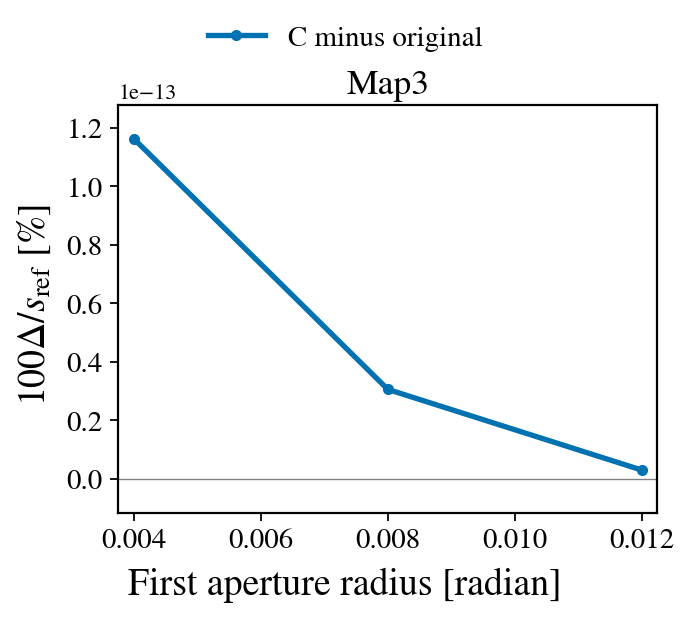

In [7]:
case = comparison_case(report=report, name="aperture_equal")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="First aperture radius [radian]",
    quantity_label="Map3, equal radii", residual="scaled", show=1,
)


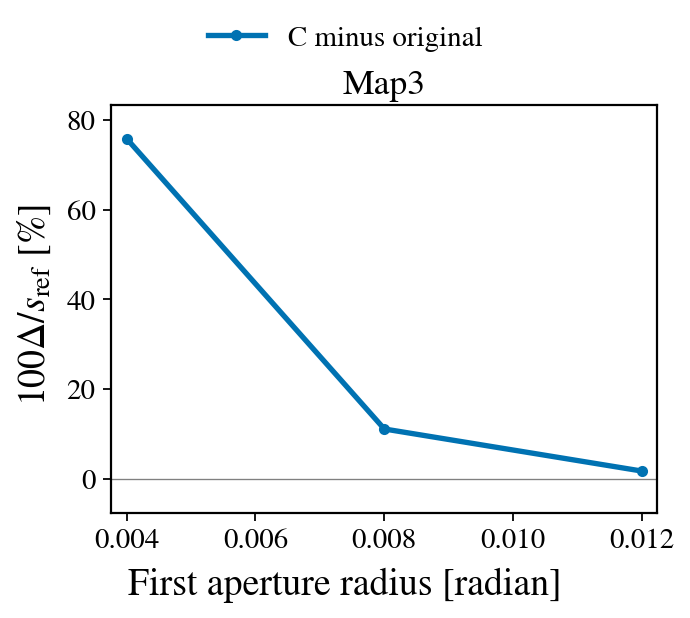

In [8]:
case = comparison_case(report=report, name="aperture_unequal")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="First aperture radius [radian]",
    quantity_label="Map3, unequal radii",
    residual="scaled", show=1,
)


## Frozen physical reference: a different kind of evidence

The matter values here come from the pinned original Python calculation, saved
once as a fixture. This cell evaluates the bundled Python matter-bispectrum theory and the
native IA calculation on the fixture's smooth power spectra and background,
then reads the saved reference back; the original matter and IA code does not run live, and the table above labels
these cases `frozen_reference` with the fixture hash.

The source's nonlinear-radius root carries a finite stopping error, so
separate tests compare the matter fit against its established allowance, check
the analytic tree limit, and evaluate squeezed triangles and all 19 IA terms
at high precision. The right-triangle ddB component has an analytic zero, and
its machine-roundoff check therefore uses the vertex amplitude rather than a
relative tolerance on zero.

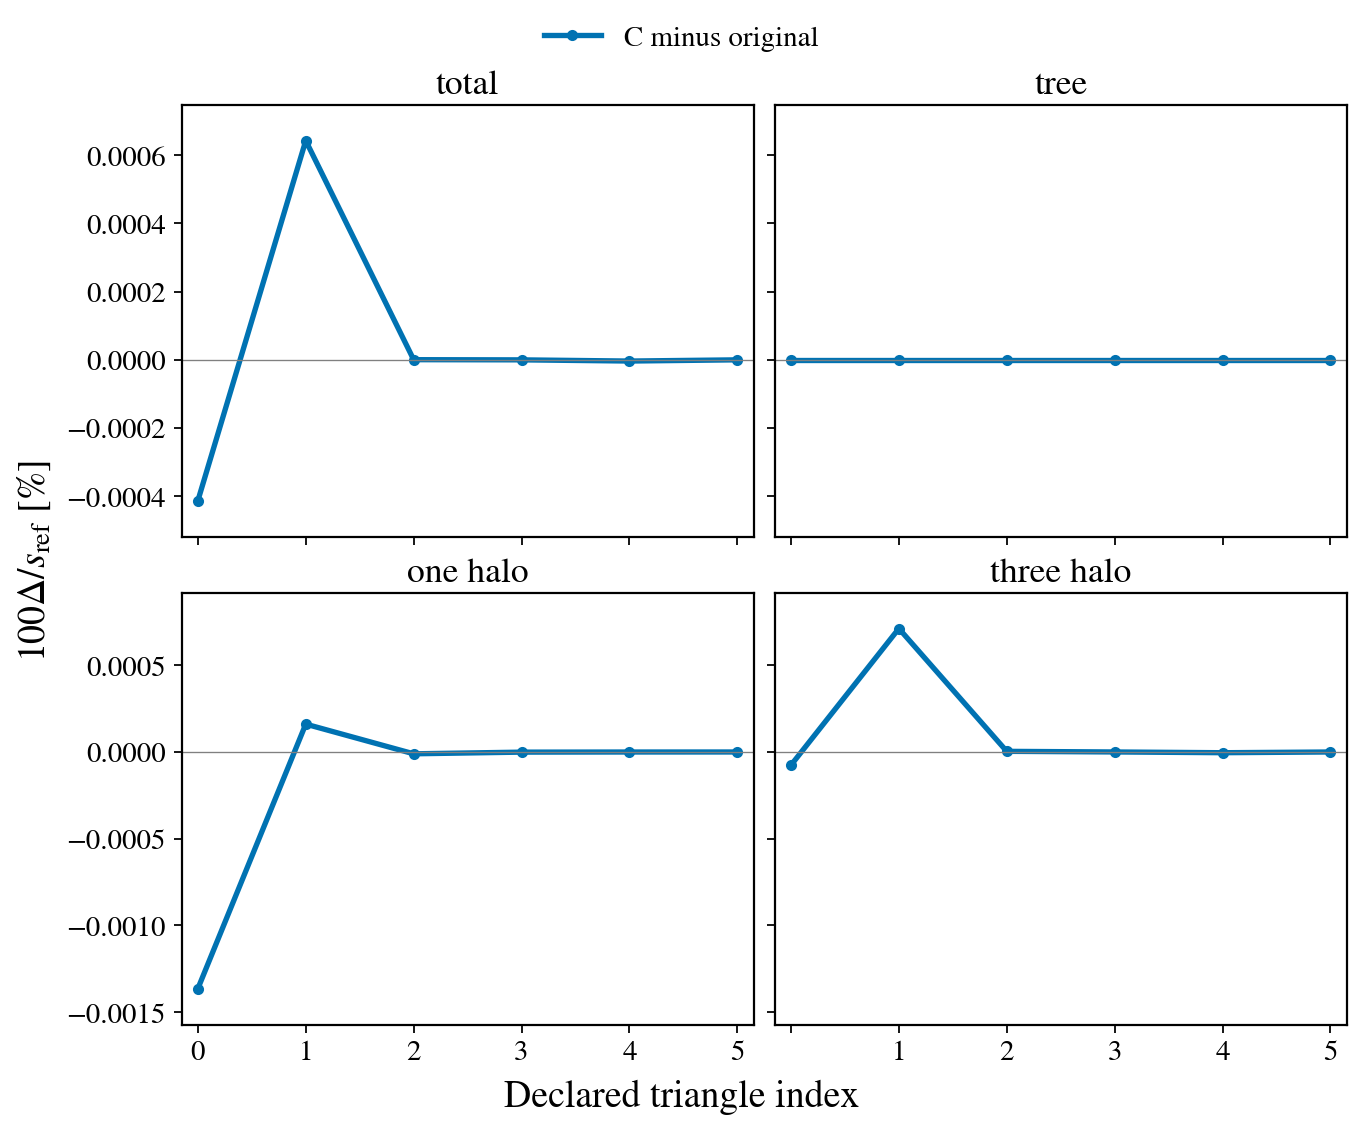

In [9]:
case = comparison_case(report=report, name="physics_matter_frozen")
arrays = load_comparison_case(case=case)
plots.plot_code_comparison(
    legend=("C minus original",), bintextpos=None,
    **arrays, coordinate_label="Declared triangle index",
    quantity_label="Matter bispectrum [(Mpc/h)^6]",
    residual="scaled", ncols=2, show=1,
)


## The archived pixel-window convention

The archived Y3 theory code (`config/3pt.ini` of the pinned
`3pcf_integrator`) multiplies the bispectrum by a HEALPix pixel window
$W_\ell$ with `nside = 1024`, one factor per leg:
$B^\mathrm{pixel}(\ell_1,\ell_2,\ell_3) = W_{\ell_1}W_{\ell_2}W_{\ell_3}B(\ell_1,\ell_2,\ell_3)$.
This section reproduces that convention and shows its effect on the Map3
rows of the joint likelihood at the `EXAMPLE_EVALUATE1` fiducial.

The convention makes four choices, kept exactly as archived:

| Choice | Value |
| --- | --- |
| Column | the scalar `TEMPERATURE` column of the official HEALPix table |
| Multipoles kept | $\ell = 0, \dots, 3\,n_\mathrm{side}-1 = 3071$, the default length of `healpy.pixwin` |
| Between integer $\ell$ | linear interpolation, done by the C model |
| Above $\ell = 3071$ | $W = 0$: an extra band limit, not part of the pixel window itself |

Scope: this is a reproduction of one archived convention, not a model of
the measurement. The DES Y3 aperture statistic is measured from the shear
catalogue with TreeCorr, so the likelihood applies no pixel window. A
pixel average on a spin-2 shear map is also a different operation from
scalar smoothing. The analytic covariance refuses a smoothed mean, and the
archived radial bank and side offset (recorded in
`tests/studies/estimator_conventions.md`) are not reproduced here.

In [10]:
# Read the HEALPix scalar window and check it against its manifest
# (data/pixel_window_manifest.yaml: source commit, sha256, nside, ell_max).
import hashlib

import numpy as np
import yaml
from astropy.io import fits

manifest = yaml.safe_load((project / "data/pixel_window_manifest.yaml").read_text())
window_file = project / "data" / manifest["path"]
nside = manifest["nside"]

if manifest["sha256"] != hashlib.sha256(window_file.read_bytes()).hexdigest():
    raise ValueError(f"{window_file} differs from its manifest; restore the file.")
if 3 * nside - 1 != manifest["ell_max"]:
    raise ValueError("The manifest's ell_max is not 3*nside - 1.")

with fits.open(window_file, memmap=False) as hdus:
    table = hdus[1]
    if nside != table.header["NSIDE"] or "TEMPERATURE" not in table.columns.names:
        raise ValueError("The FITS table is not the scalar window for this nside.")
    # Keep ell = 0..3*nside-1; the C model reads zero above the last sample.
    window = np.array(table.data["TEMPERATURE"][:3 * nside], dtype=np.float64)

print(f"W at ell = 0, 1024, 3071: {window[0]:.6f}, {window[1024]:.6f}, {window[-1]:.6f}")

W at ell = 0, 1024, 3071: 1.000000, 0.954245, 0.646451


In [11]:
# Evaluate the Cobaya likelihood once at the EXAMPLE_EVALUATE1 fiducial.
from cobaya.model import get_model
from cobaya.yaml import yaml_load_file
import cosmolike_des_3pcf_interface as ci

info = yaml_load_file(str(project / "EXAMPLE_EVALUATE1.yaml"))
fiducial = dict(info["sampler"]["evaluate"]["override"])
info.pop("sampler")
info.pop("output")
info["theory"]["camb"]["path"] = str(external / "CAMB")
model = get_model(info_or_yaml_or_file=info)
model.logposterior(params_values=fiducial, cached=False)
likelihood = model.likelihood["des_3pcf.joint_shear"]


def map3_model(pixel_window):
    # The likelihood's own constructor call (set_source_related), with the
    # same arrays and counts, plus the optional window.
    normalization = likelihood.baseline.get("metadata", {}).get(
        "linear_power_normalization", 1.0)
    counts = ci.accuracy_model_settings(
        accuracy=likelihood.accuracy, kernel_nz=likelihood.kernel_nz,
        table_boost=likelihood.table_boost, fit_nz=likelihood.fit_nz)
    return ci.production.PhysicsModelWithBispectrum(
        k=10.0**likelihood.log10k_interp_2D,
        p_linear0=likelihood.p_linear[0] * normalization,
        z=likelihood.z_interp_2D,
        p_nonlinear=likelihood.p_nonlinear,
        chi=likelihood.chi,
        dz_dchi=likelihood.dz_dchi,
        growth=likelihood.growth,
        sources=likelihood.sources,
        source_z=likelihood.source_z,
        los_z=likelihood.los_z,
        omega_m=float(likelihood.omega_m_z[0]),
        omega_m_z=likelihood.omega_m_z,
        sigma8=likelihood.sigma8,
        baseline=likelihood.baseline["native"],
        kernel_nz=counts["kernel_nz"],
        table_boost=counts["table_boost"],
        fit_nz=counts["fit_nz"],
        source_readers=False,
        feedback=likelihood.feedback,
        pixel_window=pixel_window,
    )


def map3_rows(physics):
    return likelihood.map_engine.aperture_vector(
        model=physics, ia=likelihood.ia, calibration=likelihood.calibration)


# The rebuilt unsmoothed model must give the likelihood's Map3 rows exactly;
# this checks that the copied constructor call is the likelihood's.
plain = map3_rows(physics=map3_model(pixel_window=None))
scored = likelihood.last_datavector[likelihood.map_indices]
np.testing.assert_array_equal(plain.view(np.uint64), scored.view(np.uint64))

smoothed = map3_rows(physics=map3_model(pixel_window=window))
change = 100.0 * (smoothed / plain - 1.0)
print(f"Map3 rows: {plain.size}; window change from {change.min():.3f}% to {change.max():.3f}%")

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


Map3 rows: 80; window change from -6.765% to -0.359%


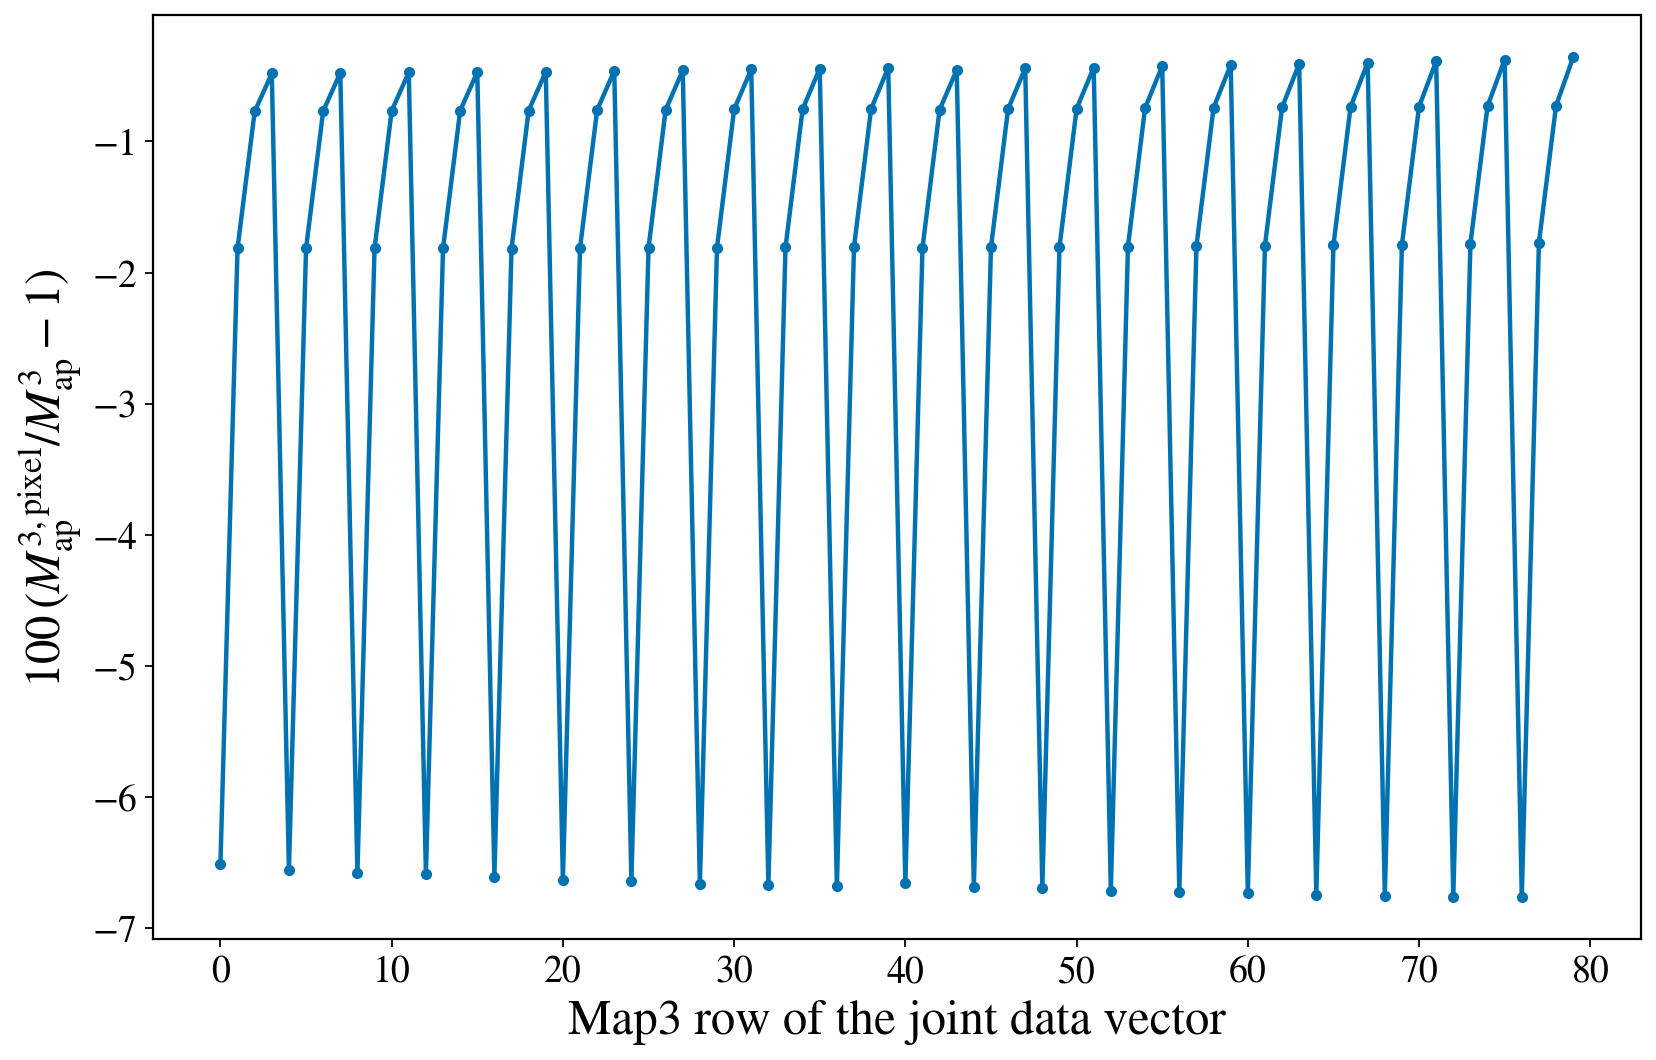

In [12]:
from matplotlib import pyplot as plt

figure, axis = plt.subplots(figsize=(12, 7.5))
axis.plot(np.arange(change.size), change, color="#0072B2", linewidth=2.0,
          marker="o", markersize=4)
axis.set_xlabel("Map3 row of the joint data vector", fontsize=22)
axis.set_ylabel(r"$100\,(M_\mathrm{ap}^{3,\mathrm{pixel}}/M_\mathrm{ap}^3 - 1)$", fontsize=22)
axis.tick_params(labelsize=17)
plt.show()

## What the result establishes

The saved arrays check source identity, Fourier and phase conventions,
finite-grid aperture weights, and the port's response to a documented source
correction. They do not check a catalogue measurement, a full original
CosmoSIS likelihood, survey masks, or final grid convergence: a DES result
still needs the specific estimator, cuts, source distributions, covariance
assumptions and numerical error budget.

Credits: fastnc is by Sunao Sugiyama and Rafael Heringer Gomes, and the
aperture routine adapts Mike Jarvis's TreeCorr implementation (Gomes et al.,
arXiv:2601.09133). Repository pins, hashes and file-level credits live in
`data/code_comparison_manifest.yaml` and
[the comparison guide](README.md#comparison).

### Matching intrinsic-alignment conventions

Production uses CosmoLike amplitudes with $C_1\rho_{\mathrm{crit}}=0.01389$ and $z_0=0.62$. An upstream calculation may instead use 0.0134 or another pivot. For a comparison of the same physical alignment, convert each amplitude by $(c_{\mathrm{up}}/0.01389)[1.62/(1+z_{\mathrm{up}})]^{\eta}$. This conversion belongs only to the comparison; production YAMLs supply CosmoLike amplitudes directly.


In [13]:
upstream_c1rho = 0.0134
upstream_pivot = 0.3
upstream_a1, upstream_eta1 = 0.8, -1.3
upstream_a2, upstream_eta2 = -0.6, 2.1
normalization_ratio = upstream_c1rho / 0.01389
pivot_ratio = 1.62 / (1.0 + upstream_pivot)
cosmolike_a1 = upstream_a1 * normalization_ratio * pivot_ratio**upstream_eta1
cosmolike_a2 = upstream_a2 * normalization_ratio * pivot_ratio**upstream_eta2
z = np.linspace(start=0.0, stop=2.0, num=21)
for amplitude, slope, converted in ((upstream_a1, upstream_eta1, cosmolike_a1),
                                    (upstream_a2, upstream_eta2, cosmolike_a2)):
    upstream = amplitude * upstream_c1rho * ((1.0 + z)/(1.0 + upstream_pivot))**slope
    cocoa = converted * 0.01389 * ((1.0 + z)/1.62)**slope
    np.testing.assert_allclose(actual=cocoa, desired=upstream, rtol=5.e-15)
